# Customer Sales Data Cleaning & Preprocessing

**Goal:** turn a messy customer sales dataset (10,200 records, 12 columns) into a reliable, analysis-ready file, and document every decision along the way.

**What's wrong with the raw data:** inconsistent spellings (8 ways to write gender), ages stored as text (`"51.0 years"`), missing values in almost every column, duplicate customers, impossible values (age 250, a purchase of 9,999,999), phone numbers that lost leading zeros, and purchase dates that fall before the signup date.

**Workflow**
1. Profile the raw data
2. Standardize text and categories
3. Parse ages, restore phone numbers, parse dates
4. Drop rows with no Customer_ID
5. Detect and mask invalid values (outliers)
6. Remove duplicate customers
7. Impute missing values (with audit flags)
8. Validate dates
9. Validate the result and summarize before vs after
10. Quick exploratory analysis
11. Export the clean file

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RAW_PATH = "../data/messy_customer_sales_data.csv"
CLEAN_PATH = "../data/clean_customer_sales_data.csv"
os.makedirs("../images", exist_ok=True)

df_raw = pd.read_csv(RAW_PATH)
df = df_raw.copy()   # all cleaning happens on a copy; the raw data stays untouched
log = {}             # collects counts at each step for the final summary
df_raw.head()

,Customer_ID,Name,Gender,Age,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Email,Phone_Number,Country
0,CUST4371,Paul Wilson,m,52.0,KOLKATA,2025-06-26,2025-05-17,26944.0,1.0,peckvictoria@example.com,2131107701,India
1,CUST5957,Jason Thomas,M,51.0 years,NaN,2021-02-17,2025-07-22,44152.0,2.0,owensanthony@example.com,1080761560,india
2,CUST3754,Brittney Martinez,F,62.0,hyderabad,2023-11-05,2024-12-08,31745.0,2.0,tara39@example.org,8981006345,India
3,CUST2934,Brenda Pierce,FEMALE,40.0,hyderabad,2022-03-13,2025-10-02,39674.0,1.0,berrynancy@example.org,8228064204,india
4,CUST5683,Matthew Carroll,f,41.0,CHENNAI,2024-04-05,2024-12-15,NaN,8.0,denise84@example.org,2665569480,India


## 1. Profile the raw data

In [2]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10200 entries, 0 to 10199
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         9177 non-null   str    
 1   Name                10200 non-null  str    
 2   Gender              9174 non-null   str    
 3   Age                 9249 non-null   str    
 4   City                9184 non-null   str    
 5   Signup_Date         10200 non-null  str    
 6   Last_Purchase_Date  9188 non-null   str    
 7   Purchase_Amount     9179 non-null   float64
 8   Feedback_Score      9177 non-null   float64
 9   Email               10200 non-null  str    
 10  Phone_Number        10200 non-null  int64  
 11  Country             9468 non-null   str    
dtypes: float64(2), int64(1), str(9)
memory usage: 956.4 KB


In [3]:
missing = df_raw.isna().sum().to_frame("missing")
missing["pct_of_rows"] = (missing["missing"] / len(df_raw) * 100).round(1)
missing

,missing,pct_of_rows
Customer_ID,1023,10.0
Name,0,0.0
Gender,1026,10.1
Age,951,9.3
City,1016,10.0
Signup_Date,0,0.0
Last_Purchase_Date,1012,9.9
Purchase_Amount,1021,10.0
Feedback_Score,1023,10.0
Email,0,0.0


In [4]:
print("Gender spellings  :", sorted(df_raw["Gender"].dropna().unique()))
print("Country labels    :", sorted(df_raw["Country"].dropna().unique()))
print("City variants     :", df_raw["City"].nunique(), "(case differences and leading spaces)")
print("Age examples      :", df_raw["Age"].dropna().sample(5, random_state=1).tolist())
print("Age 'nan years'   :", (df_raw["Age"] == "nan years").sum())
print()
print("Exact duplicate rows      :", df_raw.duplicated().sum())
print("Repeated Customer_IDs     :", df_raw["Customer_ID"].dropna().duplicated().sum())
print("Rows without Customer_ID  :", df_raw["Customer_ID"].isna().sum())
print("Phone numbers < 10 digits :", (df_raw["Phone_Number"].astype(str).str.len() < 10).sum())

log["rows_raw"] = len(df_raw)
log["missing_cells_raw"] = int(df_raw.isna().sum().sum())
log["gender_variants_raw"] = int(df_raw["Gender"].nunique())
log["city_variants_raw"] = int(df_raw["City"].nunique())
log["country_variants_raw"] = int(df_raw["Country"].nunique())
log["exact_dups_raw"] = int(df_raw.duplicated().sum())
log["repeated_ids_raw"] = int(df_raw["Customer_ID"].dropna().duplicated().sum())
log["rows_no_id"] = int(df_raw["Customer_ID"].isna().sum())
log["short_phones_raw"] = int((df_raw["Phone_Number"].astype(str).str.len() < 10).sum())

Gender spellings  : ['F', 'FEMALE', 'M', 'MALE', 'f ', 'female', 'm ', 'male']
Country labels    : ['IND', 'InDia', 'India', 'india']
City variants     : 18 (case differences and leading spaces)
Age examples      : ['21.0 years', '67.0', '25.0', '35.0 years', '67.0']
Age 'nan years'   : 64

Exact duplicate rows      : 15
Repeated Customer_IDs     : 177
Rows without Customer_ID  : 1023
Phone numbers < 10 digits : 1064


## 2. Standardize text and categories

Gender, city and country each have several spellings of the same value. I trim whitespace, normalize case, and map every variant to one label. Titles and suffixes (`Mr.`, `Dr.`, `MD`, `PhD`...) are removed from names so the field holds just the name.

In [5]:
df["Gender"] = (df["Gender"].str.strip().str.lower()
                .map({"m": "male", "male": "male", "f": "female", "female": "female"})
                .str.title())
df["City"] = df["City"].str.strip().str.title()
df["Country"] = (df["Country"].str.strip().str.lower()
                 .replace({"ind": "india"}).str.title())

print("Gender :", df["Gender"].dropna().unique().tolist())
print("City   :", sorted(df["City"].dropna().unique()))
print("Country:", df["Country"].dropna().unique().tolist())

Gender : ['Male', 'Female']
City   : ['Bangalore', 'Chennai', 'Delhi', 'Hyderabad', 'Kolkata', 'Mumbai']
Country: ['India']


In [6]:
title_pattern = r"^(?:Mr|Mrs|Ms|Miss|Dr)\.?\s+"
suffix_pattern = r"(?:\s+(?:Jr\.?|Sr\.?|II|III|IV|MD|DDS|DVM|PhD))+$"

has_affix = df["Name"].str.contains(title_pattern) | df["Name"].str.contains(suffix_pattern)
df["Name"] = (df["Name"].str.replace(title_pattern, "", regex=True)
              .str.replace(suffix_pattern, "", regex=True)
              .str.strip())
log["names_fixed"] = int(has_affix.sum())
print("Names with a title or suffix removed:", log["names_fixed"])
df["Name"].head()

Names with a title or suffix removed: 415


,Name
0,Paul Wilson
1,Jason Thomas
2,Brittney Martinez
3,Brenda Pierce
4,Matthew Carroll


## 3. Parse ages, restore phone numbers, parse dates

- **Age** is stored as text (`"51.0 years"`, `"nan years"`). A regex pulls out the number.
- **Phone numbers** are 10 digits but were stored as integers, so any leading zero was dropped. Every short number has 6-9 digits, which matches that explanation, so I pad them back to 10 digits and store the field as text.
- **Dates** are converted to proper datetimes.

In [7]:
# Age: "51.0 years" -> 51.0 ("nan years" becomes NaN)
df["Age"] = pd.to_numeric(df["Age"].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0], errors="coerce")

# Phone: restore leading zeros lost when stored as integers
df["Phone_Number"] = df["Phone_Number"].astype(str).str.zfill(10)

# Dates: text -> datetime
for col in ["Signup_Date", "Last_Purchase_Date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

print("Phone numbers restored to 10 digits:", log["short_phones_raw"])
print("Phone length counts now:", df["Phone_Number"].str.len().value_counts().to_dict())
df[["Age", "Phone_Number", "Signup_Date", "Last_Purchase_Date"]].dtypes

Phone numbers restored to 10 digits: 1064
Phone length counts now: {10: 10200}


,0
Age,float64
Phone_Number,str
Signup_Date,datetime64[us]
Last_Purchase_Date,datetime64[us]


## 4. Drop rows with no Customer_ID

A record with no ID can't be matched to a customer or de-duplicated. First I check whether the missing IDs could be recovered through the email address.

In [8]:
has_id = df["Customer_ID"].notna()
recoverable = df.loc[~has_id, "Email"].isin(df.loc[has_id, "Email"]).sum()
print(f"Rows without Customer_ID: {(~has_id).sum():,}")
print(f"...of which share an email with a known customer: {recoverable}  (not worth special handling)")

df = df.dropna(subset=["Customer_ID"]).reset_index(drop=True)
print(f"Rows remaining: {len(df):,}")

Rows without Customer_ID: 1,023
...of which share an email with a known customer: 32  (not worth special handling)
Rows remaining: 9,177


## 5. Detect and mask invalid values

Two approaches are compared:

1. **Statistical:** a z-score filter (|z| > 3) on Age and Purchase_Amount.
2. **Domain rules:** customers must be adults (18-100) and a purchase must be positive and below 100,000.

The z-score catches the extreme values, but misses subtle invalid ones. A negative purchase of -500 or an age of 3 is not statistically extreme, yet both are impossible. So I use the **domain rules** for the actual fix, and mask invalid values as missing (rather than deleting the customer) so a valid record isn't lost because of one bad field.

In [9]:
numeric_cols = ["Age", "Purchase_Amount"]
z_flag = np.abs(stats.zscore(df[numeric_cols], nan_policy="omit")) > 3

for i, col in enumerate(numeric_cols):
    flagged = sorted(df.loc[z_flag[:, i], col].unique().tolist())
    print(f"z-score |z| > 3 in {col:16s}: {z_flag[:, i].sum()} rows -> {flagged}")

z-score |z| > 3 in Age             : 7 rows -> [250.0]
z-score |z| > 3 in Purchase_Amount : 4 rows -> [9999999.0]


In [10]:
before = df[numeric_cols].copy()

AGE_MIN, AGE_MAX = 18, 100
AMOUNT_MIN, AMOUNT_MAX = 0, 100_000   # a valid amount is > 0 and < 100,000

bad_age = df["Age"].notna() & ~df["Age"].between(AGE_MIN, AGE_MAX)
bad_amount = df["Purchase_Amount"].notna() & ~(
    (df["Purchase_Amount"] > AMOUNT_MIN) & (df["Purchase_Amount"] < AMOUNT_MAX))

print("Invalid ages    :", int(bad_age.sum()), sorted(df.loc[bad_age, "Age"].unique().tolist()))
print("Invalid amounts :", int(bad_amount.sum()), sorted(df.loc[bad_amount, "Purchase_Amount"].unique().tolist()))

caught_by_z = int((z_flag[:, 0] & bad_age.to_numpy()).sum() + (z_flag[:, 1] & bad_amount.to_numpy()).sum())
print(f"Caught by the z-score filter: {caught_by_z} of {int(bad_age.sum() + bad_amount.sum())}")

log["invalid_ages"] = int(bad_age.sum())
log["invalid_amounts"] = int(bad_amount.sum())
df.loc[bad_age, "Age"] = np.nan
df.loc[bad_amount, "Purchase_Amount"] = np.nan

Invalid ages    : 15 [3.0, 10.0, 250.0]
Invalid amounts : 13 [-500.0, 0.0, 9999999.0]
Caught by the z-score filter: 11 of 28


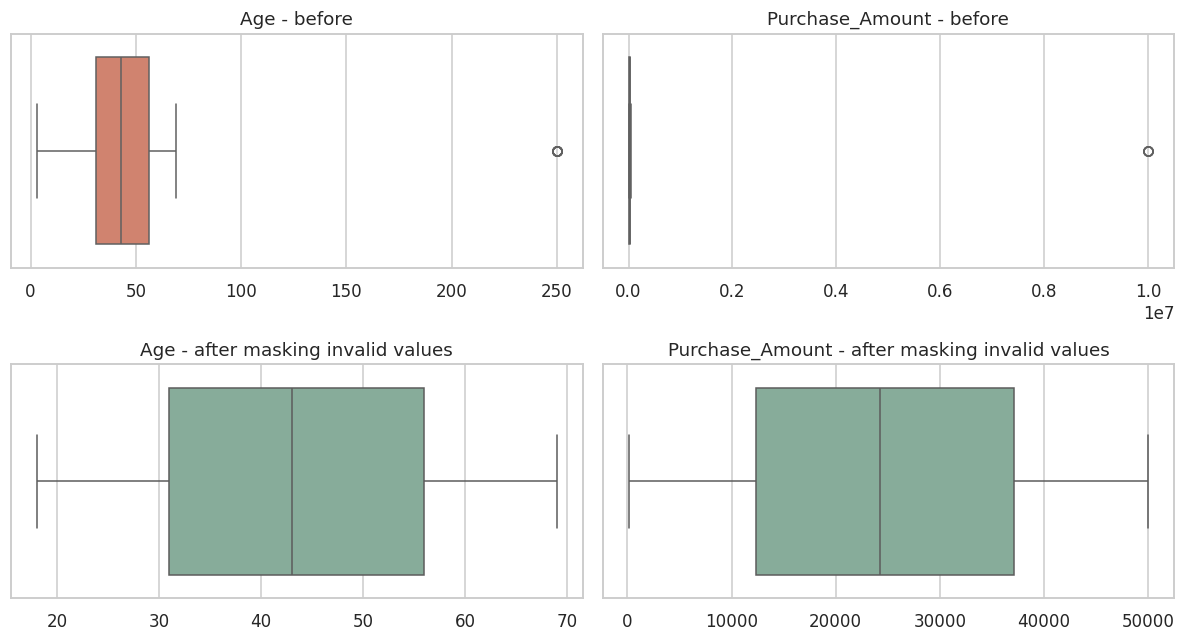

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for j, col in enumerate(numeric_cols):
    sns.boxplot(x=before[col], ax=axes[0, j], color="#e07a5f")
    axes[0, j].set_title(f"{col} - before")
    sns.boxplot(x=df[col], ax=axes[1, j], color="#81b29a")
    axes[1, j].set_title(f"{col} - after masking invalid values")
    for ax in axes[:, j]:
        ax.set_xlabel("")
plt.tight_layout()
plt.savefig("../images/outliers_before_after.png", dpi=130, bbox_inches="tight")
plt.show()

## 6. Remove duplicate customers

Before merging, I confirm that repeated IDs really are the same customer. Where copies of a record differ only in which fields are blank, I keep the first non-missing value of each field, so no information is lost.

In [12]:
repeated = df[df["Customer_ID"].duplicated(keep=False)]
distinct = repeated.groupby("Customer_ID")[["Name", "Email"]].nunique().max()
print(f"Repeated IDs: {repeated['Customer_ID'].nunique()}  |  max distinct names / emails per ID: {distinct.to_dict()}")

rows_before = len(df)
df = df.groupby("Customer_ID", as_index=False, sort=False).first()
log["dup_rows_removed"] = rows_before - len(df)
print(f"Merged {log['dup_rows_removed']} duplicate rows -> {len(df):,} unique customers")

Repeated IDs: 177  |  max distinct names / emails per ID: {'Name': 1, 'Email': 1}
Merged 177 duplicate rows -> 9,000 unique customers


## 7. Impute missing values

Imputation is done **after** standardizing and de-duplicating, so the fill values are calculated from clean data.

| Column | Method | Why |
|---|---|---|
| Age, Purchase_Amount, Feedback_Score | Median | Robust to skew; keeps the field numeric |
| Gender, City | `"Unknown"` category | Filling every gap with the most common value would invent demographic data and skew the split |
| Country | Only value present | All known records are India |
| Last_Purchase_Date | Left blank | A date can't be sensibly inferred |

Each imputed numeric field gets a `*_Imputed` flag column, so analysts can exclude filled values when needed.

In [13]:
for col in ["Age", "Purchase_Amount", "Feedback_Score"]:
    df[f"{col}_Imputed"] = df[col].isna()
    median = df[col].median()
    df[col] = df[col].fillna(median)
    print(f"{col:16s}: filled {df[f'{col}_Imputed'].sum():,} values with the median ({median:,.0f})")

log["gender_unknown"] = int(df["Gender"].isna().sum())
log["city_unknown"] = int(df["City"].isna().sum())
log["country_filled"] = int(df["Country"].isna().sum())
df["Gender"] = df["Gender"].fillna("Unknown")
df["City"] = df["City"].fillna("Unknown")
df["Country"] = df["Country"].fillna(df["Country"].mode()[0])

df["Age"] = df["Age"].round().astype(int)
df["Feedback_Score"] = df["Feedback_Score"].round().astype(int)

log["values_filled"] = int(df[["Age_Imputed", "Purchase_Amount_Imputed", "Feedback_Score_Imputed"]].sum().sum()
                           + log["gender_unknown"] + log["city_unknown"] + log["country_filled"])
print("Total values filled:", f"{log['values_filled']:,}")

Age             : filled 911 values with the median (43)
Purchase_Amount : filled 919 values with the median (24,287)
Feedback_Score  : filled 887 values with the median (6)
Total values filled: 5,180


## 8. Validate dates

A last purchase can't happen before the customer signed up. Those rows are **flagged, not changed**, because there's no way to know which of the two dates is wrong.

In [14]:
df["Last_Purchase_Before_Signup"] = df["Last_Purchase_Date"] < df["Signup_Date"]
log["date_conflicts"] = int(df["Last_Purchase_Before_Signup"].sum())
log["missing_last_purchase"] = int(df["Last_Purchase_Date"].isna().sum())

print(f"Customers whose last purchase is before signup: {log['date_conflicts']:,} "
      f"({log['date_conflicts'] / len(df):.1%})")
print(f"Customers with no last-purchase date (left blank): {log['missing_last_purchase']:,}")

Customers whose last purchase is before signup: 823 (9.1%)
Customers with no last-purchase date (left blank): 903


## 9. Validate the result and compare before vs after

In [15]:
final_cols = ["Customer_ID", "Name", "Gender", "Age", "City", "Country",
              "Signup_Date", "Last_Purchase_Date", "Purchase_Amount", "Feedback_Score",
              "Email", "Phone_Number",
              "Age_Imputed", "Purchase_Amount_Imputed", "Feedback_Score_Imputed",
              "Last_Purchase_Before_Signup"]
df = df[final_cols]

# Automated checks: the notebook fails loudly if any rule is broken
assert df["Customer_ID"].notna().all() and df["Customer_ID"].is_unique
assert df["Age"].between(AGE_MIN, AGE_MAX).all()
assert ((df["Purchase_Amount"] > AMOUNT_MIN) & (df["Purchase_Amount"] < AMOUNT_MAX)).all()
assert df["Feedback_Score"].between(1, 10).all()
assert df["Phone_Number"].str.len().eq(10).all()
assert set(df["Gender"]) <= {"Male", "Female", "Unknown"}
assert df["Country"].nunique() == 1
print("All validation checks passed")

remaining = df.isna().sum()
remaining[remaining > 0].to_frame("still_missing")

All validation checks passed


,still_missing
Last_Purchase_Date,903


In [16]:
known_gender = df.loc[df["Gender"] != "Unknown", "Gender"].nunique()
known_city = df.loc[df["City"] != "Unknown", "City"].nunique()

summary = pd.DataFrame([
    ("Rows",                              f"{log['rows_raw']:,}",           f"{len(df):,}"),
    ("Rows without Customer_ID",          f"{log['rows_no_id']:,}",         "0"),
    ("Exact duplicate rows",              f"{log['exact_dups_raw']}",       f"{int(df.duplicated().sum())}"),
    ("Repeated Customer_IDs",             f"{log['repeated_ids_raw']}",     f"{int(df['Customer_ID'].duplicated().sum())}"),
    ("Missing cells",                     f"{log['missing_cells_raw']:,}",  f"{int(df.isna().sum().sum()):,} (purchase dates)"),
    ("Gender spellings",                  f"{log['gender_variants_raw']}",  f"{known_gender} (+ Unknown)"),
    ("City variants",                     f"{log['city_variants_raw']}",    f"{known_city} (+ Unknown)"),
    ("Country labels",                    f"{log['country_variants_raw']}", f"{df['Country'].nunique()}"),
    ("Age format",                        "text (\"51.0 years\")",          "integer"),
    ("Invalid ages / amounts",            "not checked",                    f"{log['invalid_ages']} / {log['invalid_amounts']} masked, then imputed"),
    ("Phone numbers under 10 digits",     f"{log['short_phones_raw']:,}",   "0"),
    ("Last purchase before signup",       "not checked",                    f"{log['date_conflicts']:,} flagged"),
], columns=["Metric", "Before", "After"])
summary

,Metric,Before,After
0,Rows,"10,200","9,000"
1,Rows without Customer_ID,"1,023",0
2,Exact duplicate rows,15,0
3,Repeated Customer_IDs,177,0
4,Missing cells,"7,804",903 (purchase dates)
5,Gender spellings,8,2 (+ Unknown)
6,City variants,18,6 (+ Unknown)
7,Country labels,4,1
8,Age format,"text (""51.0 years"")",integer
9,Invalid ages / amounts,not checked,"15 / 13 masked, then imputed"


## 10. Quick exploratory analysis

With clean data, a few questions become easy to answer. Rows whose value was imputed are **excluded** from each calculation using the flag columns, so the results reflect real observations only.

In [17]:
known = df[~df["Purchase_Amount_Imputed"] & (df["City"] != "Unknown")]
city = (known.groupby("City")
        .agg(customers=("Customer_ID", "count"),
             total_purchase=("Purchase_Amount", "sum"),
             avg_purchase=("Purchase_Amount", "mean"))
        .round(0).sort_values("total_purchase", ascending=False))
city

,customers,total_purchase,avg_purchase
City,,,
Delhi,1227,30926895.0,25205.0
Bangalore,1209,30595810.0,25307.0
Mumbai,1227,30367823.0,24750.0
Hyderabad,1193,29675015.0,24874.0
Kolkata,1208,29355225.0,24301.0
Chennai,1205,28839850.0,23933.0


In [18]:
rated = df[~df["Feedback_Score_Imputed"] & ~df["Age_Imputed"]].copy()
rated["Age_Group"] = pd.cut(rated["Age"], bins=[17, 24, 34, 44, 54, 64, 100],
                            labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"])
age_groups = (rated.groupby("Age_Group", observed=True)
              .agg(customers=("Customer_ID", "count"), avg_feedback=("Feedback_Score", "mean"))
              .round(2))
age_groups

,customers,avg_feedback
Age_Group,,
18-24,958,5.46
25-34,1405,5.64
35-44,1434,5.41
45-54,1428,5.42
55-64,1376,5.50
65+,694,5.45


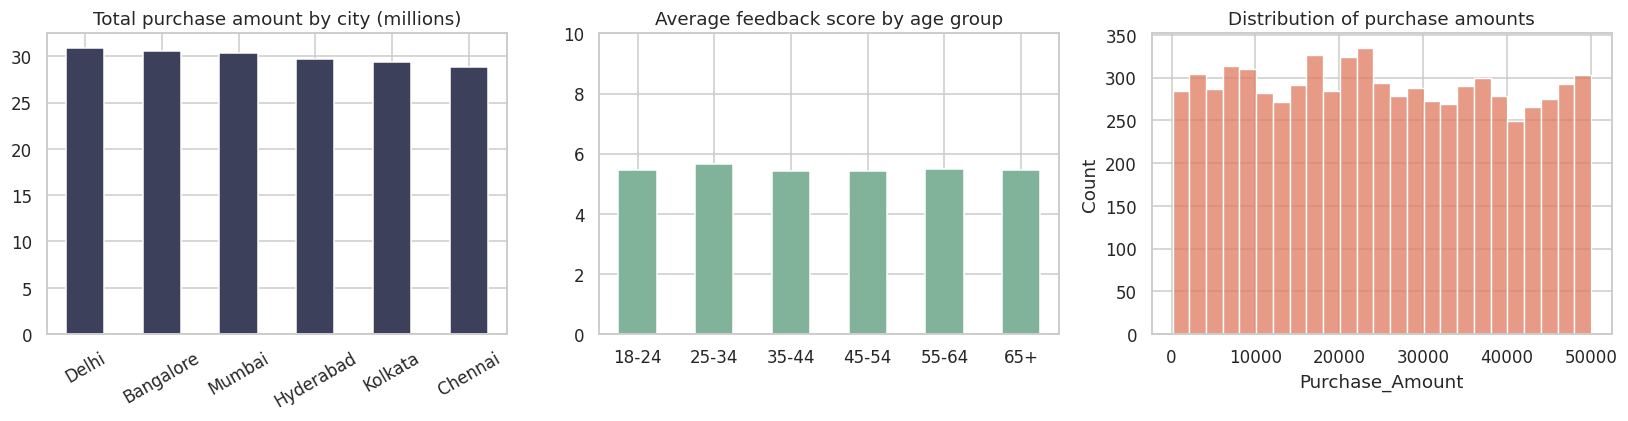

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

(city["total_purchase"] / 1e6).plot.bar(ax=axes[0], color="#3d405b", rot=30)
axes[0].set_title("Total purchase amount by city (millions)")
axes[0].set_xlabel("")

age_groups["avg_feedback"].plot.bar(ax=axes[1], color="#81b29a", rot=0)
axes[1].set_title("Average feedback score by age group")
axes[1].set_xlabel("")
axes[1].set_ylim(0, 10)

sns.histplot(known["Purchase_Amount"], bins=25, ax=axes[2], color="#e07a5f")
axes[2].set_title("Distribution of purchase amounts")
axes[2].set_xlabel("Purchase_Amount")

plt.tight_layout()
plt.savefig("../images/eda_summary.png", dpi=130, bbox_inches="tight")
plt.show()

In [20]:
top_city = city["total_purchase"].idxmax()
avg_gap = (city["avg_purchase"].max() - city["avg_purchase"].min()) / city["avg_purchase"].mean()
fb_gap = age_groups["avg_feedback"].max() - age_groups["avg_feedback"].min()
signup_years = df["Signup_Date"].dt.year.value_counts().sort_index()

print(f"Highest total purchase amount : {top_city} ({city.loc[top_city, 'total_purchase']:,.0f})")
print(f"Spread of average purchase across cities : {avg_gap:.1%} of the overall average")
print(f"Spread of average feedback across age groups : {fb_gap:.2f} points (on a 1-10 scale)")
print("Signups per year:", signup_years.to_dict())

Highest total purchase amount : Delhi (30,926,895)
Spread of average purchase across cities : 5.6% of the overall average
Spread of average feedback across age groups : 0.23 points (on a 1-10 scale)
Signups per year: {2020: 409, 2021: 1749, 2022: 1866, 2023: 1786, 2024: 1778, 2025: 1412}


**Takeaway:** this dataset is fairly uniform. Average purchase differs by only about 6% across the six cities, average feedback sits between 5.4 and 5.6 for every age group, and purchase amounts are spread almost evenly from 0 to 50,000. No single segment stands out, so any further analysis would need to combine several fields or add more data (for example product or channel). Signups are steady at roughly 1,750-1,870 per year from 2021 to 2024; 2020 and 2025 are partial years because the data runs from October 2020 to October 2025.

## 11. Export the clean dataset

In [21]:
df.to_csv(CLEAN_PATH, index=False)
print(f"Saved {len(df):,} rows x {df.shape[1]} columns to {CLEAN_PATH}")
df.head()

Saved 9,000 rows x 16 columns to ../data/clean_customer_sales_data.csv


,Customer_ID,Name,Gender,Age,City,Country,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Email,Phone_Number,Age_Imputed,Purchase_Amount_Imputed,Feedback_Score_Imputed,Last_Purchase_Before_Signup
0,CUST4371,Paul Wilson,Male,52,Kolkata,India,2025-06-26,2025-05-17,26944.0,1,peckvictoria@example.com,2131107701,False,False,False,True
1,CUST5957,Jason Thomas,Male,51,Unknown,India,2021-02-17,2025-07-22,44152.0,2,owensanthony@example.com,1080761560,False,False,False,False
2,CUST3754,Brittney Martinez,Female,62,Hyderabad,India,2023-11-05,2024-12-08,31745.0,2,tara39@example.org,8981006345,False,False,False,False
3,CUST2934,Brenda Pierce,Female,40,Hyderabad,India,2022-03-13,2025-10-02,39674.0,1,berrynancy@example.org,8228064204,False,False,False,False
4,CUST5683,Matthew Carroll,Female,41,Chennai,India,2024-04-05,2024-12-15,24287.0,8,denise84@example.org,2665569480,False,True,False,False
